In [1]:
import sqlite3 as sq3
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
con = sq3.connect("opioid.db")
sql = con.cursor()
annual = pd.read_sql_query("SELECT * from annual", con)
land = pd.read_sql_query("SELECT * from land", con)
population = pd.read_sql_query("SELECT * from population", con)
con.close()

In [3]:
annual.head()

,?,BUYER_COUNTY,BUYER_STATE,year,count,DOSAGE_UNIT,countyfips
0,1,ABBEVILLE,SC,2006,877,363620,45001
1,2,ABBEVILLE,SC,2007,908,402940,45001
2,3,ABBEVILLE,SC,2008,871,424590,45001
3,4,ABBEVILLE,SC,2009,930,467230,45001
4,5,ABBEVILLE,SC,2010,1197,539280,45001


In [4]:
land.head()

,?,Areaname,STCOU,LND010190F,LND010190D,LND010190N1,LND010190N2,LND010200F,LND010200D,LND010200N1,...,LND110210N1,LND110210N2,LND210190F,LND210190D,LND210190N1,LND210190N2,LND210200F,LND210200D,LND210200N1,LND210200N2
0,1,UNITED STATES,00000,0,3787425.08,0000,0000,0,3794083.06,0000,...,0000,0000,0,251083.35,0000,0000,0,256644.62,0000,0000
1,2,ALABAMA,01000,0,52422.94,0000,0000,0,52419.02,0000,...,0000,0000,0,1672.71,0000,0000,0,1675.01,0000,0000
2,3,"Autauga, AL",01001,0,604.49,0000,0000,0,604.45,0000,...,0000,0000,0,8.48,0000,0000,0,8.48,0000,0000
3,4,"Baldwin, AL",01003,0,2027.08,0000,0000,0,2026.93,0000,...,0000,0000,0,430.55,0000,0000,0,430.58,0000,0000
4,5,"Barbour, AL",01005,0,904.59,0000,0000,0,904.52,0000,...,0000,0000,0,19.59,0000,0000,0,19.61,0000,0000


In [5]:
population.head()

,?,BUYER_COUNTY,BUYER_STATE,countyfips,STATE,COUNTY,county_name,NAME,variable,year,population
0,1,AUTAUGA,AL,01001,1,1,Autauga,"Autauga County, Alabama",B01003_001,2006,51328
1,2,BALDWIN,AL,01003,1,3,Baldwin,"Baldwin County, Alabama",B01003_001,2006,168121
2,3,BARBOUR,AL,01005,1,5,Barbour,"Barbour County, Alabama",B01003_001,2006,27861
3,4,BIBB,AL,01007,1,7,Bibb,"Bibb County, Alabama",B01003_001,2006,22099
4,5,BLOUNT,AL,01009,1,9,Blount,"Blount County, Alabama",B01003_001,2006,55485


In [6]:
annual.loc[(annual["BUYER_STATE"] == "AR") & (annual["BUYER_COUNTY"] == "MONTGOMERY"), "countyfips"] = "05097"
annual = annual[annual["BUYER_COUNTY"].notna()].copy()
annual.head()

,?,BUYER_COUNTY,BUYER_STATE,year,count,DOSAGE_UNIT,countyfips
0,1,ABBEVILLE,SC,2006,877,363620,45001
1,2,ABBEVILLE,SC,2007,908,402940,45001
2,3,ABBEVILLE,SC,2008,871,424590,45001
3,4,ABBEVILLE,SC,2009,930,467230,45001
4,5,ABBEVILLE,SC,2010,1197,539280,45001


In [7]:
land_area = land[["Areaname", "STCOU", "LND110210D"]].copy()
land_area = land_area.rename(columns={"STCOU": "countyfips"})
land_area.head()

,Areaname,countyfips,LND110210D
0,UNITED STATES,00000,3531905.43
1,ALABAMA,01000,50645.33
2,"Autauga, AL",01001,594.44
3,"Baldwin, AL",01003,1589.78
4,"Barbour, AL",01005,884.88


In [8]:
county_info = population.merge(land_area, on="countyfips", how="left")
county_info.head()

,?,BUYER_COUNTY,BUYER_STATE,countyfips,STATE,COUNTY,county_name,NAME,variable,year,population,Areaname,LND110210D
0,1,AUTAUGA,AL,01001,1,1,Autauga,"Autauga County, Alabama",B01003_001,2006,51328,"Autauga, AL",594.44
1,2,BALDWIN,AL,01003,1,3,Baldwin,"Baldwin County, Alabama",B01003_001,2006,168121,"Baldwin, AL",1589.78
2,3,BARBOUR,AL,01005,1,5,Barbour,"Barbour County, Alabama",B01003_001,2006,27861,"Barbour, AL",884.88
3,4,BIBB,AL,01007,1,7,Bibb,"Bibb County, Alabama",B01003_001,2006,22099,"Bibb, AL",622.58
4,5,BLOUNT,AL,01009,1,9,Blount,"Blount County, Alabama",B01003_001,2006,55485,"Blount, AL",644.78


In [9]:
opioid = annual.merge(county_info, on=["countyfips", "year"], how="left", suffixes=("_annual", "_population"))
opioid.head()

,?_annual,BUYER_COUNTY_annual,BUYER_STATE_annual,year,count,DOSAGE_UNIT,countyfips,?_population,BUYER_COUNTY_population,BUYER_STATE_population,STATE,COUNTY,county_name,NAME,variable,population,Areaname,LND110210D
0,1,ABBEVILLE,SC,2006,877,363620,45001,2313,ABBEVILLE,SC,45,1,Abbeville,"Abbeville County, South Carolina",B01003_001,25821,"Abbeville, SC",490.48
1,2,ABBEVILLE,SC,2007,908,402940,45001,5455,ABBEVILLE,SC,45,1,Abbeville,"Abbeville County, South Carolina",B01003_001,25745,"Abbeville, SC",490.48
2,3,ABBEVILLE,SC,2008,871,424590,45001,8597,ABBEVILLE,SC,45,1,Abbeville,"Abbeville County, South Carolina",B01003_001,25699,"Abbeville, SC",490.48
3,4,ABBEVILLE,SC,2009,930,467230,45001,11737,ABBEVILLE,SC,45,1,Abbeville,"Abbeville County, South Carolina",B01003_001,25347,"Abbeville, SC",490.48
4,5,ABBEVILLE,SC,2010,1197,539280,45001,14877,ABBEVILLE,SC,45,1,Abbeville,"Abbeville County, South Carolina",B01003_001,25643,"Abbeville, SC",490.48


In [10]:
opioid["DOSAGE_UNIT"] = pd.to_numeric(opioid["DOSAGE_UNIT"], errors="coerce")
opioid["population"] = pd.to_numeric(opioid["population"], errors="coerce")

opioid["pills_per_person"] = (opioid["DOSAGE_UNIT"] / opioid["population"])

opioid[["BUYER_COUNTY_annual", "BUYER_STATE_annual", "year", "DOSAGE_UNIT", "population", "pills_per_person"]].head()

,BUYER_COUNTY_annual,BUYER_STATE_annual,year,DOSAGE_UNIT,population,pills_per_person
0,ABBEVILLE,SC,2006,363620.0,25821.0,14.082336
1,ABBEVILLE,SC,2007,402940.0,25745.0,15.651194
2,ABBEVILLE,SC,2008,424590.0,25699.0,16.521655
3,ABBEVILLE,SC,2009,467230.0,25347.0,18.433345
4,ABBEVILLE,SC,2010,539280.0,25643.0,21.030301


In [11]:
avg_by_year = opioid.groupby("year", as_index=False)["pills_per_person"].mean()
avg_by_year

,year,pills_per_person
0,2006,28.783799
1,2007,32.474087
2,2008,35.503895
3,2009,39.094975
4,2010,41.532509
5,2011,45.035734
6,2012,45.651077
7,2013,44.422536
8,2014,43.269444


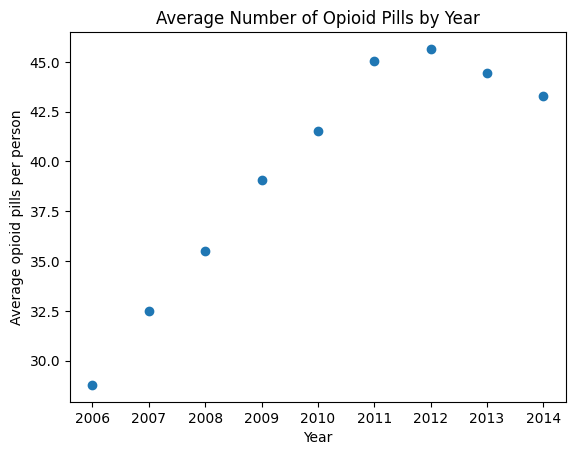

In [12]:
plt.scatter(avg_by_year["year"], avg_by_year["pills_per_person"])
plt.xlabel("Year")
plt.ylabel("Average opioid pills per person")
plt.title("Average Number of Opioid Pills by Year")
plt.show()

# R kernel execution

In [13]:
import os
# do not run this cell if you are grading my assignment
os.environ["R_HOME"] = r"C:\Program Files\R\R-4.6.1"
os.environ["PATH"] = (r"C:\rtools45\usr\bin"  + os.pathsep + r"C:\rtools45\x86_64-w64-mingw32.static.posix\bin"  + os.pathsep + os.environ["PATH"])
R_HOME = r"C:\Program Files\R\R-4.6.1"

In [14]:
import json
import rpy2.robjects as ro

with open("hw4_R.ipynb", "r") as f:
    r_notebook = json.load(f)
r_code = ""
for cell in r_notebook["cells"]:
    r_code += "".join(cell["source"]) + "\n"
ro.r(r_code)

In [15]:
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter

r_opioid = ro.globalenv["opioid"]
with localconverter(ro.default_converter + pandas2ri.converter):
    opioid_from_r = ro.conversion.rpy2py(r_opioid)

opioid_from_r.head()

,countyfips,year,X_annual,BUYER_COUNTY_annual,BUYER_STATE_annual,count,DOSAGE_UNIT,X_population,BUYER_COUNTY_population,BUYER_STATE_population,STATE,COUNTY,county_name,NAME,variable,population,Areaname,LND110210D
1,NA,2006,22236,SAINT THOMAS,VI,628,219100.0,-2147483648,NA_character_,NA_character_,-2147483648,-2147483648,NA_character_,NA_character_,NA_character_,-2147483648,NA_character_,NaN
2,NA,2006,15684,MANATI,PR,382,159260.0,-2147483648,NA_character_,NA_character_,-2147483648,-2147483648,NA_character_,NA_character_,NA_character_,-2147483648,NA_character_,NaN
3,NA,2006,17151,MOCA,PR,160,129300.0,-2147483648,NA_character_,NA_character_,-2147483648,-2147483648,NA_character_,NA_character_,NA_character_,-2147483648,NA_character_,NaN
4,NA,2006,18015,NARANJITO,PR,321,86500.0,-2147483648,NA_character_,NA_character_,-2147483648,-2147483648,NA_character_,NA_character_,NA_character_,-2147483648,NA_character_,NaN
5,NA,2006,767,ARECIBO,PR,532,280100.0,-2147483648,NA_character_,NA_character_,-2147483648,-2147483648,NA_character_,NA_character_,NA_character_,-2147483648,NA_character_,NaN
